---
title: "Laboratorio 1 - Series de Tiempo"
author:
  - "Ihan Marroquin - 23108"
  - "Diego Patzan - 23525"
date: "26 de julio de 2026"
---

# CC3084 - Data Science

**Universidad del Valle de Guatemala**  
**Catedrático:** Erick Marroquin

Este cuaderno contiene el código completo, los resultados y las visualizaciones del Laboratorio 1. El informe formal sin código se encuentra en `docs/Informe_Laboratorio1_Series_de_Tiempo.pdf`.


## 1. Objetivo y decisiones metodológicas

El conjunto de datos registra el ingreso mensual de viajeros internacionales a Guatemala. El análisis utiliza únicamente **Turista + Excursionista**, porque estas categorías son comparables a lo largo de todo el período. Se analizan siete series:

1. Total mensual de viajeros.
2. Las tres categorías principales de `Región dos`.
3. Las tres fronteras con mayor acumulado.

La selección del Top 3 se realiza con el acumulado de todo el período y cada serie se divide cronológicamente en aproximadamente 70% de entrenamiento y 30% de prueba.


In [1]:
from pathlib import Path
import json
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

try:
    from prophet import Prophet
    PROPHET_AVAILABLE = True
except Exception:
    Prophet = None
    PROPHET_AVAILABLE = False


def find_project_root():
    start = Path.cwd().resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "raw" / "Base_Migracion_2009-2026jun.xlsx").exists():
            return candidate
    raise FileNotFoundError("No se encontró data/raw/Base_Migracion_2009-2026jun.xlsx")

ROOT = find_project_root()
RAW_FILE = ROOT / "data" / "raw" / "Base_Migracion_2009-2026jun.xlsx"
PROCESSED_DIR = ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Proyecto localizado correctamente.")
print("Prophet disponible:", PROPHET_AVAILABLE)


Proyecto localizado correctamente.
Prophet disponible: False


## 2. Carga y preparación de los datos

El archivo crudo se conserva sin modificaciones. Se crea una fecha mensual a partir de `Año` y `Mes cod`, se convierte `Viajero` a numérico y se normalizan espacios en las variables categóricas.


In [2]:
df_raw = pd.read_excel(RAW_FILE)
df = df_raw.copy()

categorical_cols = [
    "Mes", "Vía", "Frontera", "País", "Región", "Región dos",
    "Regiones OMT", "MCEO", "Agrupación Residencia", "Tipo de Viajero"
]
for col in categorical_cols:
    df[col] = df[col].astype("string").str.strip()

df["Año"] = pd.to_numeric(df["Año"], errors="coerce").astype("Int64")
df["Mes cod"] = pd.to_numeric(df["Mes cod"], errors="coerce").astype("Int64")
df["Viajero"] = pd.to_numeric(df["Viajero"], errors="coerce")
df["Fecha"] = pd.to_datetime(
    dict(year=df["Año"].astype(int), month=df["Mes cod"].astype(int), day=1)
)

display(df.head())
print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")
print("Período:", df["Fecha"].min().strftime("%Y-%m"), "a", df["Fecha"].max().strftime("%Y-%m"))


,Año,Mes cod,Mes,Vía,Frontera,País,Región,Región dos,Regiones OMT,MCEO,Agrupación Residencia,Tipo de Viajero,Viajero,Fecha
0,2009,1,Ene,Aérea,01 La Aurora,Albania,OTROS EUROPEOS,Europa,EUROPA MERIDIONAL,08 OTROS,Europa,Turista,1.0,2009-01-01
1,2009,1,Ene,Aérea,01 La Aurora,Alemania,EUROPA,Europa,EUROPA OCCIDENTAL,04 EUROPA,Europa,Turista,716.0,2009-01-01
2,2009,1,Ene,Aérea,01 La Aurora,Angola,OTROS PAISES DEL MUNDO,Otros Paises Del Mundo,ÁFRICA CENTRAL,08 OTROS,Resto del Mundo,Turista,4.0,2009-01-01
3,2009,1,Ene,Aérea,01 La Aurora,Arabia Saudita,OTROS ORIENTE MEDIO,Oriente Medio,ORIENTE MEDIO,08 OTROS,Resto del Mundo,Turista,5.0,2009-01-01
4,2009,1,Ene,Aérea,01 La Aurora,Argelia,OTROS PAISES DEL MUNDO,Otros Paises Del Mundo,ÁFRICA DEL NORTE,08 OTROS,Resto del Mundo,Turista,1.0,2009-01-01


Dimensiones: 161,036 filas x 14 columnas
Período: 2009-01 a 2026-06


## 3. Análisis exploratorio general

Se revisan valores faltantes, duplicados, estadísticas descriptivas, posibles valores atípicos y los cruces solicitados: evolución temporal, países o mercados, regiones, vías y fronteras.


In [3]:
missing = df.isna().sum().sort_values(ascending=False).rename("Faltantes").to_frame()
missing["Porcentaje"] = 100 * missing["Faltantes"] / len(df)
duplicates = int(df.duplicated().sum())

display(missing)
print("Duplicados exactos:", f"{duplicates:,}")
display(df["Viajero"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).to_frame())

q1, q3 = df["Viajero"].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = ((df["Viajero"] < lower) | (df["Viajero"] > upper)).sum()
print(f"Atípicos según IQR: {outliers:,} ({100*outliers/len(df):.2f}%)")
print("Estos valores no se eliminan automáticamente, porque los registros agregados de mercados grandes pueden ser legítimamente altos.")


,Faltantes,Porcentaje
Año,0,0.0
Mes cod,0,0.0
Mes,0,0.0
Vía,0,0.0
Frontera,0,0.0
País,0,0.0
Región,0,0.0
Región dos,0,0.0
Regiones OMT,0,0.0
MCEO,0,0.0


Duplicados exactos: 0


,Viajero
count,161036.000000
mean,324.697193
std,2387.745140
min,0.000000
25%,2.000000
50%,7.000000
75%,38.891667
95%,858.261181
99%,6113.919887
max,92336.035067


Atípicos según IQR: 26,390 (16.39%)
Estos valores no se eliminan automáticamente, porque los registros agregados de mercados grandes pueden ser legítimamente altos.


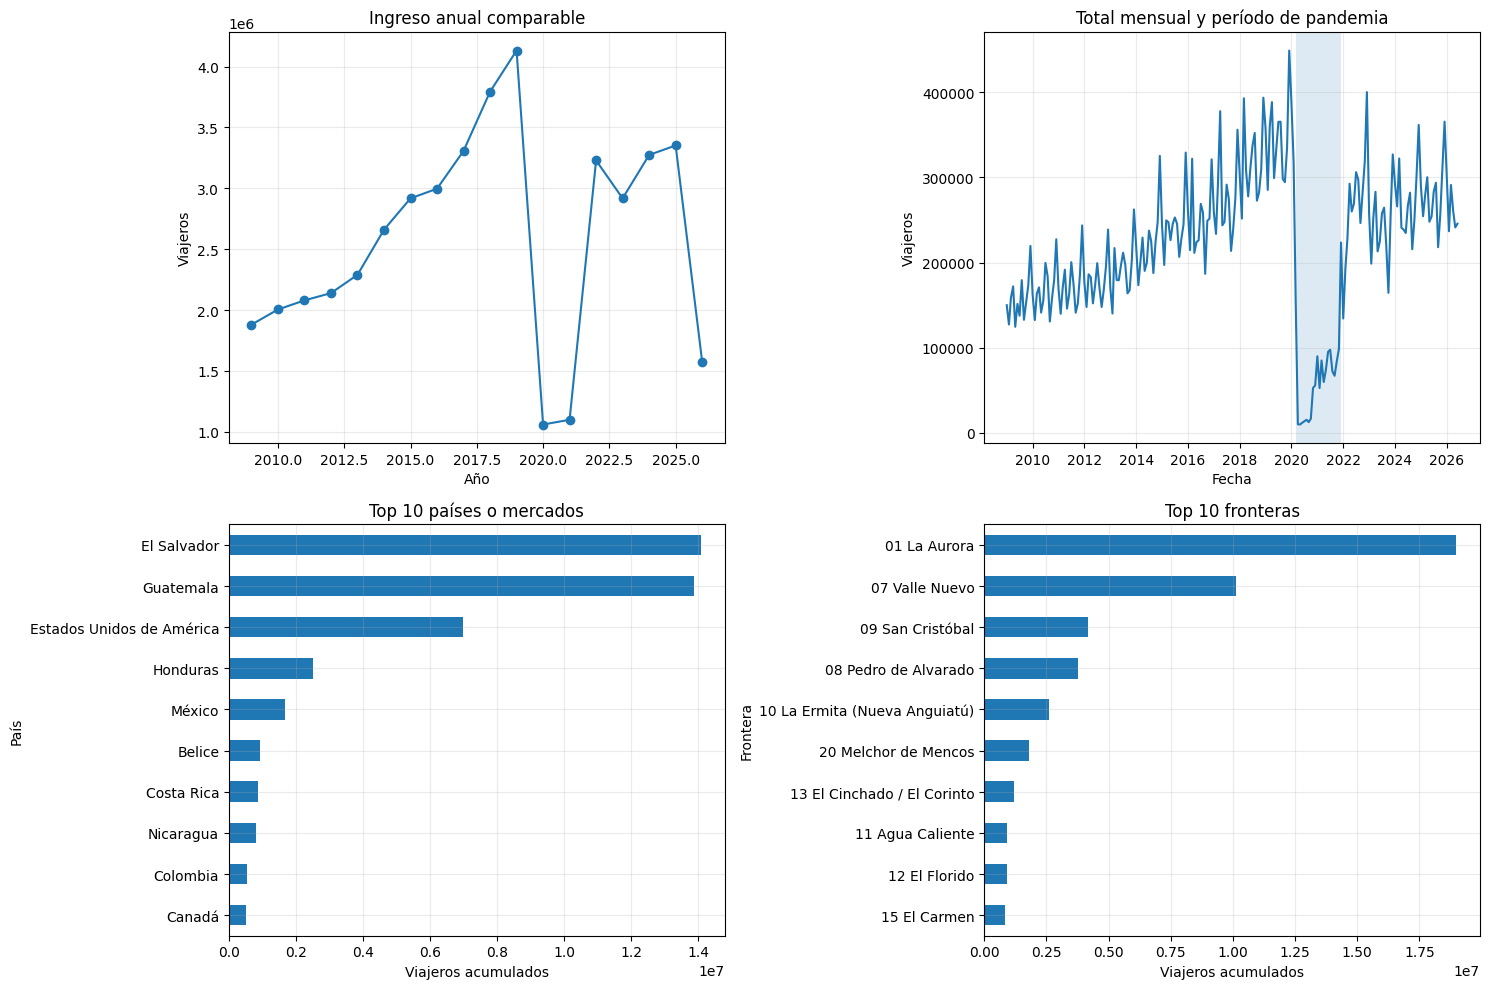

,Top países/mercados,Top regiones
0,,821.0
América Del Centro,,33283931.980144
América Del Norte,,9160810.151218
América Del Sur y el Caribe,,1413590.324412
Asia,,410333.513065
Belice,916101.074634,
Canadá,516707.889907,
Colombia,549494.68556,
Costa Rica,860240.685423,
El Salvador,14079135.771435,


,Viajeros
Vía,
Terrestre,2.759225e+07
Aérea,1.901942e+07
Marítima,1.002410e+05


In [4]:
consistent_types = ["Turista", "Excursionista"]
df_comp = df[df["Tipo de Viajero"].isin(consistent_types)].copy()

annual = df_comp.groupby("Año", as_index=False)["Viajero"].sum()
monthly_total = df_comp.groupby("Fecha")["Viajero"].sum().asfreq("MS", fill_value=0)

top_countries = df_comp.groupby("País")["Viajero"].sum().sort_values(ascending=False).head(10)
top_regions = df_comp.groupby("Región dos")["Viajero"].sum().sort_values(ascending=False).head(10)
top_vias = df_comp.groupby("Vía")["Viajero"].sum().sort_values(ascending=False)
top_frontiers = df_comp.groupby("Frontera")["Viajero"].sum().sort_values(ascending=False).head(10)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes[0,0].plot(annual["Año"], annual["Viajero"], marker="o")
axes[0,0].set_title("Ingreso anual comparable")
axes[0,0].set_xlabel("Año"); axes[0,0].set_ylabel("Viajeros")

axes[0,1].plot(monthly_total.index, monthly_total.values)
axes[0,1].axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-01"), alpha=0.15)
axes[0,1].set_title("Total mensual y período de pandemia")
axes[0,1].set_xlabel("Fecha"); axes[0,1].set_ylabel("Viajeros")

top_countries.sort_values().plot.barh(ax=axes[1,0])
axes[1,0].set_title("Top 10 países o mercados")
axes[1,0].set_xlabel("Viajeros acumulados")

top_frontiers.sort_values().plot.barh(ax=axes[1,1])
axes[1,1].set_title("Top 10 fronteras")
axes[1,1].set_xlabel("Viajeros acumulados")

plt.tight_layout(); plt.show()

display(pd.DataFrame({"Top países/mercados": top_countries, "Top regiones": top_regions}).fillna(""))
display(top_vias.rename("Viajeros").to_frame())


### Interpretación exploratoria

La serie presenta una tendencia de crecimiento antes de 2020, una ruptura extraordinaria durante la pandemia y una recuperación posterior. Los países, regiones y fronteras están muy concentrados: unas pocas categorías explican una proporción importante del total. La vía terrestre concentra el mayor volumen acumulado, mientras que la vía aérea tiene un papel especialmente importante en los mercados de larga distancia. Los atípicos del campo `Viajero` se interpretan con cautela y no se eliminan, porque la unidad de observación ya representa conteos agregados.


## 4. Construcción de las series y división 70/30

Se seleccionan las tres regiones y las tres fronteras con mayor acumulado del período completo. Después se crean series mensuales continuas y se divide cada una sin barajar los datos.


In [5]:
selected_regions = top_regions.head(3).index.tolist()
selected_frontiers = top_frontiers.head(3).index.tolist()

series = {"Total mensual": monthly_total}
for region in selected_regions:
    s = (df_comp[df_comp["Región dos"] == region]
         .groupby("Fecha")["Viajero"].sum()
         .reindex(monthly_total.index, fill_value=0))
    series[f"Región - {region}"] = s
for frontier in selected_frontiers:
    s = (df_comp[df_comp["Frontera"] == frontier]
         .groupby("Fecha")["Viajero"].sum()
         .reindex(monthly_total.index, fill_value=0))
    series[f"Frontera - {frontier}"] = s

series_df = pd.DataFrame(series)
series_df.index.name = "Fecha"
series_df.to_csv(PROCESSED_DIR / "series_mensuales.csv", encoding="utf-8-sig")

split = int(len(series_df) * 0.70)
print("Regiones seleccionadas:", selected_regions)
print("Fronteras seleccionadas:", selected_frontiers)
print(f"Observaciones totales: {len(series_df)} | entrenamiento: {split} | prueba: {len(series_df)-split}")
print("Entrenamiento:", series_df.index[0].strftime("%Y-%m"), "a", series_df.index[split-1].strftime("%Y-%m"))
print("Prueba:", series_df.index[split].strftime("%Y-%m"), "a", series_df.index[-1].strftime("%Y-%m"))
display(series_df.head())


Regiones seleccionadas: ['América Del Centro', 'América Del Norte', 'Europa']
Fronteras seleccionadas: ['01 La Aurora', '07 Valle Nuevo', '09 San Cristóbal']
Observaciones totales: 210 | entrenamiento: 147 | prueba: 63
Entrenamiento: 2009-01 a 2021-03
Prueba: 2021-04 a 2026-06


,Total mensual,Región - América Del Centro,Región - América Del Norte,Región - Europa,Frontera - 01 La Aurora,Frontera - 07 Valle Nuevo,Frontera - 09 San Cristóbal
Fecha,,,,,,,
2009-01-01,149944.029345,93848.087646,36033.941699,12061.0,81271.0,16204.815818,8495.004016
2009-02-01,127303.692203,73988.387264,33970.304940,12642.0,69663.0,17754.437037,6972.000000
2009-03-01,158795.673819,96398.150900,41482.522919,13676.0,84051.0,27236.744710,12785.024596
2009-04-01,172013.467694,114286.682101,39595.785593,10562.0,80247.0,36564.959498,7681.602680
2009-05-01,124559.524351,83304.469915,29239.054436,6245.0,64456.0,26924.008001,5112.796082


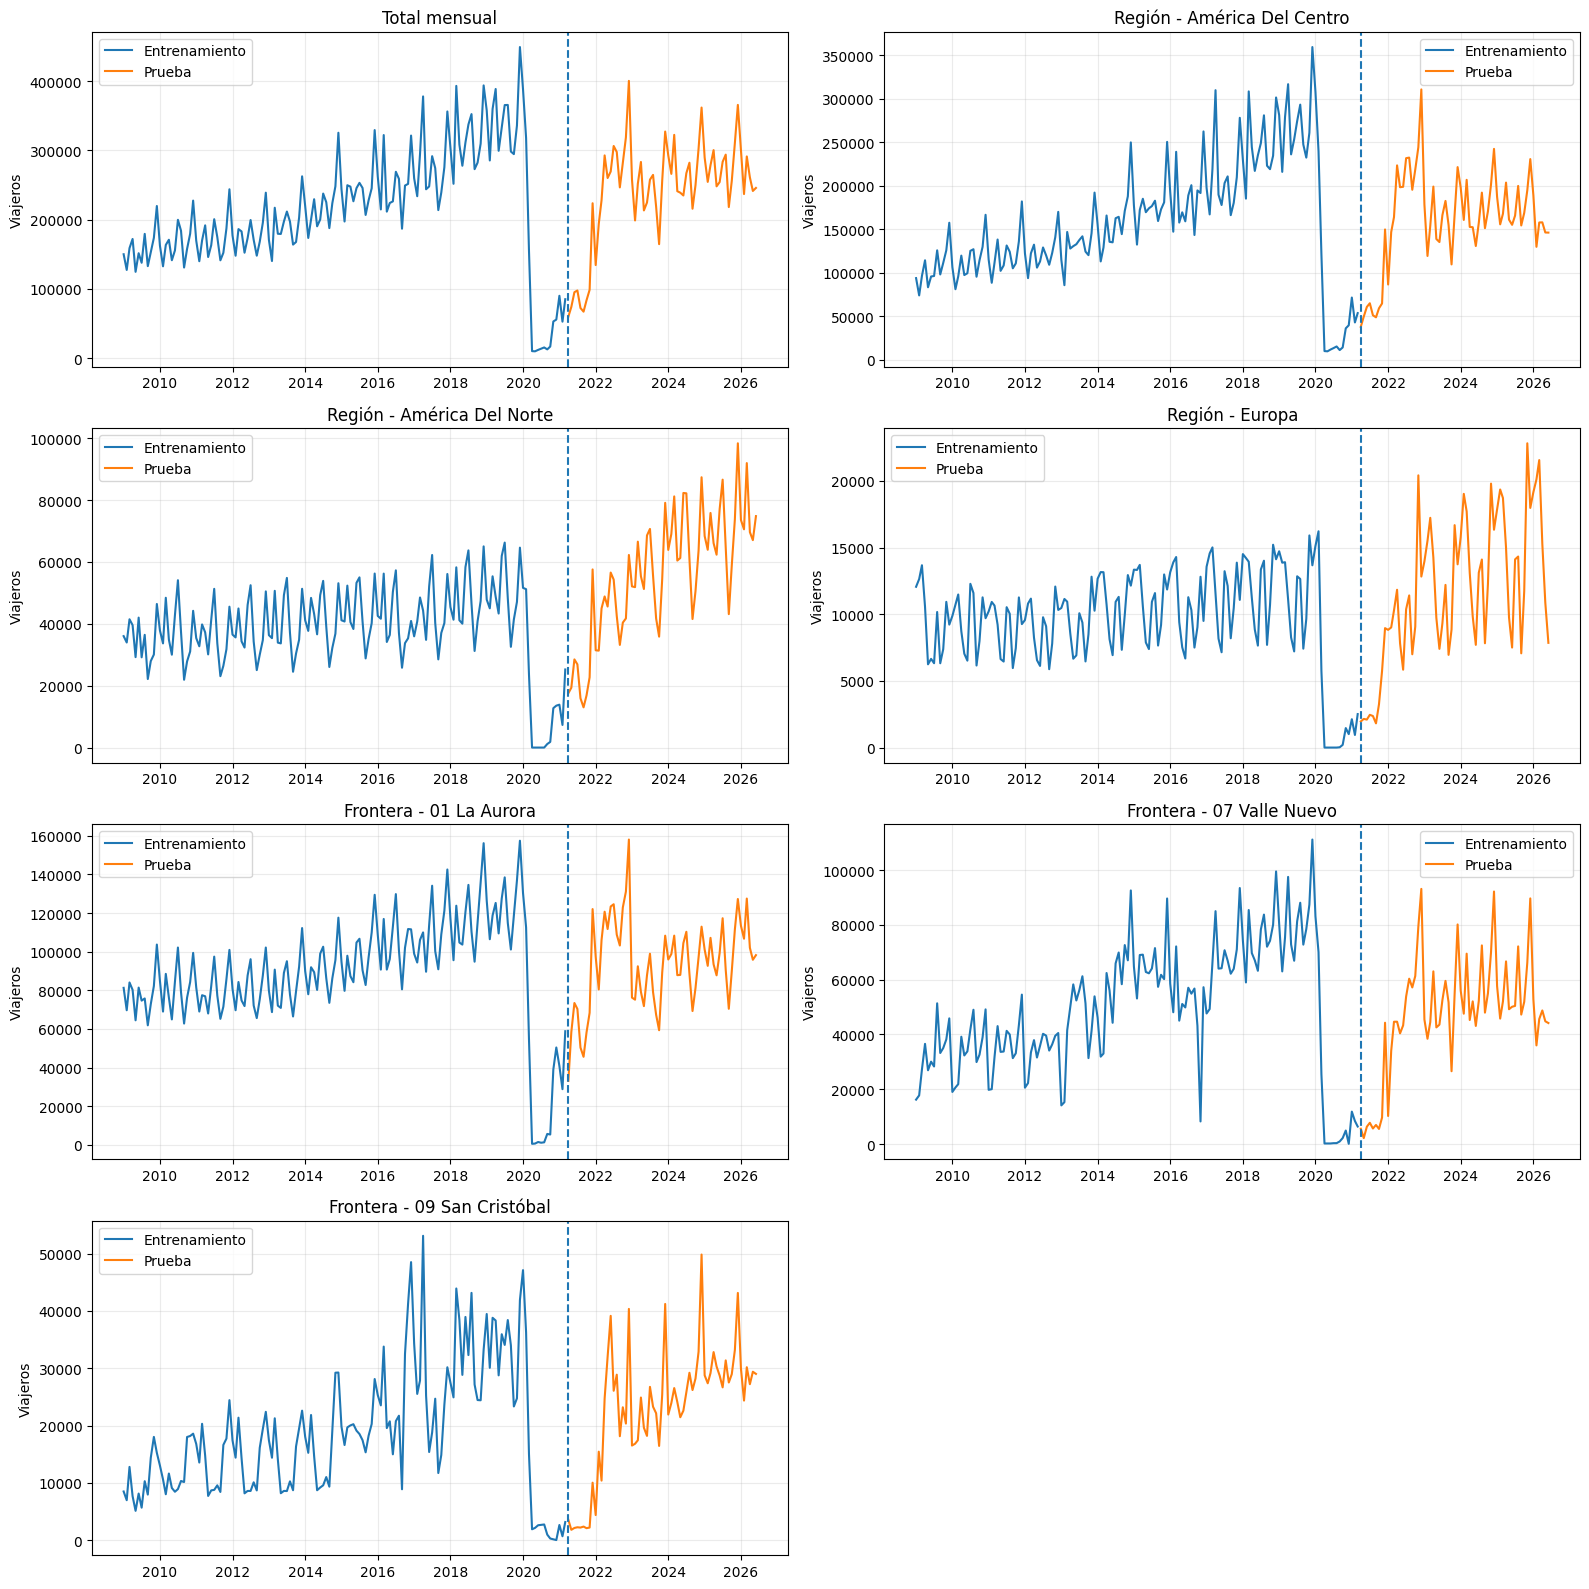

In [6]:
fig, axes = plt.subplots(4, 2, figsize=(16, 16))
for ax, (name, s) in zip(axes.ravel(), series_df.items()):
    ax.plot(s.index[:split], s.iloc[:split], label="Entrenamiento")
    ax.plot(s.index[split:], s.iloc[split:], label="Prueba")
    ax.axvline(s.index[split], linestyle="--")
    ax.set_title(name)
    ax.set_ylabel("Viajeros")
    ax.legend()
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()


## 5. Funciones de análisis y modelado

Para cada serie se aplica `log(1 + y)` cuando es necesario estabilizar la varianza. La prueba ADF determina el número mínimo de diferenciaciones. ACF y PACF se utilizan para proponer órdenes pequeños y parsimoniosos. Se comparan ARIMA/SARIMA, suavizamiento exponencial simple, Holt-Winters, seasonal naive y Prophet.


In [7]:
def adf_summary(values):
    result = adfuller(np.asarray(values, dtype=float), autolag="AIC")
    return {"ADF": result[0], "p_value": result[1], "lags": result[2]}


def choose_d(log_values):
    if adf_summary(log_values)["p_value"] <= 0.05:
        return 0
    if adf_summary(np.diff(log_values))["p_value"] <= 0.05:
        return 1
    return 2


def suggest_pq(stationary):
    # Propuesta simple y reproducible basada en correlaciones iniciales.
    x = np.asarray(stationary, dtype=float)
    x = x - x.mean()
    max_lag = min(6, len(x)//4)
    acfs = [abs(np.corrcoef(x[:-lag], x[lag:])[0,1]) for lag in range(1, max_lag+1)]
    q = int(np.argmax(acfs) + 1) if acfs else 1
    q = min(max(q, 1), 2)
    # Se mantienen órdenes pequeños para evitar sobreajuste; PACF se inspecciona gráficamente.
    p = 1 if len(x) < 100 else 2
    return p, q


def error_metrics(actual, predicted):
    predicted = np.maximum(0, np.asarray(predicted, dtype=float))
    return mean_absolute_error(actual, predicted), math.sqrt(mean_squared_error(actual, predicted))


def seasonal_naive(train, horizon, period=12):
    last = np.asarray(train[-period:], dtype=float)
    return np.array([last[i % period] for i in range(horizon)])


def additive_fallback(train, horizon):
    y = np.log1p(np.asarray(train, dtype=float))
    n = len(y)
    t_all = np.arange(n + horizon, dtype=float)
    cps = np.quantile(np.arange(n), np.linspace(0.15, 0.85, 10)).astype(int)
    def features(t):
        cols = [np.ones(len(t)), t]
        cols += [np.maximum(0, t-cp) for cp in cps]
        for k in range(1, 6):
            cols += [np.sin(2*np.pi*k*t/12), np.cos(2*np.pi*k*t/12)]
        return np.column_stack(cols)
    model = Ridge(alpha=10, fit_intercept=False).fit(features(t_all[:n]), y)
    return np.maximum(0, np.expm1(model.predict(features(t_all[n:]))))


def prophet_prediction(train, train_index, test_index):
    if PROPHET_AVAILABLE:
        frame = pd.DataFrame({"ds": train_index, "y": train})
        model = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
        model.fit(frame)
        pred = model.predict(pd.DataFrame({"ds": test_index}))["yhat"].to_numpy()
        return np.maximum(0, pred), "Prophet"
    return additive_fallback(train, len(test_index)), "Prophet - respaldo aditivo"


In [8]:
def analyze_one_series(name, s, split_index):
    values = s.to_numpy(dtype=float)
    train, test = values[:split_index], values[split_index:]
    train_idx, test_idx = s.index[:split_index], s.index[split_index:]
    log_train = np.log1p(train)
    d = choose_d(log_train)
    stationary = np.diff(log_train, n=d) if d else log_train
    p, q = suggest_pq(stationary)

    stl = STL(log_train, period=12, robust=True).fit()
    seasonal_strength = max(0.0, 1 - np.var(stl.resid) / np.var(stl.seasonal + stl.resid))
    volatility = float(np.std(np.diff(np.log1p(values))))

    # Modelos ARIMA/SARIMA propuestos a partir de d y de órdenes pequeños observados en ACF/PACF.
    candidates = [
        ((p, d, 0), (0,0,0,12), f"ARIMA({p},{d},0)"),
        ((0, d, q), (0,0,0,12), f"ARIMA(0,{d},{q})"),
        ((p, d, q), (0,0,0,12), f"ARIMA({p},{d},{q})"),
        ((p, d, q), (1,0,1,12), f"SARIMA({p},{d},{q})(1,0,1,12)"),
    ]
    rows = []
    predictions = {}
    residual_map = {}
    for order, seasonal_order, label in candidates:
        try:
            fit = SARIMAX(
                log_train, order=order, seasonal_order=seasonal_order,
                trend="c" if d == 0 else "n",
                enforce_stationarity=False, enforce_invertibility=False
            ).fit(disp=False, maxiter=150)
            pred = np.maximum(0, np.expm1(fit.get_forecast(len(test)).predicted_mean))
            mae, rmse = error_metrics(test, pred)
            resid = np.asarray(fit.resid); resid = resid[np.isfinite(resid)]
            lb_p = acorr_ljungbox(resid, lags=[min(12, max(1, len(resid)//5))], return_df=True)["lb_pvalue"].iloc[0]
            rows.append([name, label, str(order), str(seasonal_order), mae, rmse, fit.aic, fit.bic, lb_p])
            predictions[label] = pred
            residual_map[label] = resid
        except Exception as exc:
            print(name, label, "no convergió:", exc)

    ses = SimpleExpSmoothing(train, initialization_method="estimated").fit()
    pred = np.maximum(0, ses.forecast(len(test)))
    mae, rmse = error_metrics(test, pred)
    rows.append([name, "Suavizamiento exponencial simple", "", "", mae, rmse, np.nan, np.nan, np.nan])
    predictions["Suavizamiento exponencial simple"] = pred

    hw = ExponentialSmoothing(train, trend="add", damped_trend=True, seasonal="add", seasonal_periods=12,
                              initialization_method="estimated").fit(optimized=True, use_brute=False)
    pred = np.maximum(0, hw.forecast(len(test)))
    mae, rmse = error_metrics(test, pred)
    rows.append([name, "Holt-Winters aditivo", "", "", mae, rmse, np.nan, np.nan, np.nan])
    predictions["Holt-Winters aditivo"] = pred

    pred = seasonal_naive(train, len(test))
    mae, rmse = error_metrics(test, pred)
    rows.append([name, "Seasonal naive", "", "", mae, rmse, np.nan, np.nan, np.nan])
    predictions["Seasonal naive"] = pred

    pred, prophet_name = prophet_prediction(train, train_idx, test_idx)
    mae, rmse = error_metrics(test, pred)
    rows.append([name, prophet_name, "", "", mae, rmse, np.nan, np.nan, np.nan])
    predictions[prophet_name] = pred

    cols = ["Serie", "Modelo", "Orden", "Orden estacional", "MAE", "RMSE", "AIC", "BIC", "Ljung-Box p"]
    metrics_df = pd.DataFrame(rows, columns=cols).sort_values(["RMSE", "MAE"]).reset_index(drop=True)
    best_name = metrics_df.loc[0, "Modelo"]

    pre = s.loc["2019-01-01":"2019-12-01"].mean()
    covid = s.loc["2020-04-01":"2021-03-01"].mean()
    pandemic_drop = 1 - covid/pre if pre > 0 else np.nan
    recovery = s.loc["2022-01-01":]
    recovery_growth = np.polyfit(np.arange(len(recovery)), np.log1p(recovery.values), 1)[0]

    info = {
        "Serie": name,
        "Inicio": s.index.min().strftime("%Y-%m"),
        "Fin": s.index.max().strftime("%Y-%m"),
        "Frecuencia": "Mensual (12 por año)",
        "d": d, "p sugerido": p, "q sugerido": q,
        "ADF original p": adf_summary(train)["p_value"],
        "ADF log p": adf_summary(log_train)["p_value"],
        "ADF estacionaria p": adf_summary(stationary)["p_value"],
        "Fuerza estacional": seasonal_strength,
        "Volatilidad": volatility,
        "Caída pandemia": pandemic_drop,
        "Crecimiento recuperación": recovery_growth,
        "Mejor modelo": best_name,
        "MAE mejor": metrics_df.loc[0, "MAE"],
        "RMSE mejor": metrics_df.loc[0, "RMSE"],
    }
    return metrics_df, info, stl, stationary, predictions, residual_map


## 6. Ejecución del análisis de las siete series

La siguiente celda ajusta todos los modelos. Puede tardar varios minutos. Los resultados se guardan también en `data/processed/`.


In [9]:
all_metrics = []
all_info = []
analysis_objects = {}

for name, s in series_df.items():
    print("Analizando:", name)
    m, info, stl, stationary, predictions, residuals = analyze_one_series(name, s, split)
    all_metrics.append(m)
    all_info.append(info)
    analysis_objects[name] = {
        "stl": stl, "stationary": stationary,
        "predictions": predictions, "residuals": residuals
    }

metrics_df = pd.concat(all_metrics, ignore_index=True)
info_df = pd.DataFrame(all_info)
metrics_df.to_csv(PROCESSED_DIR / "comparacion_modelos.csv", index=False, encoding="utf-8-sig")
info_df.to_csv(PROCESSED_DIR / "resumen_series.csv", index=False, encoding="utf-8-sig")

display(info_df)


Analizando: Total mensual


Analizando: Región - América Del Centro


Analizando: Región - América Del Norte


Analizando: Región - Europa


Analizando: Frontera - 01 La Aurora


Analizando: Frontera - 07 Valle Nuevo


Analizando: Frontera - 09 San Cristóbal


,Serie,Inicio,Fin,Frecuencia,d,p sugerido,q sugerido,ADF original p,ADF log p,ADF estacionaria p,Fuerza estacional,Volatilidad,Caída pandemia,Crecimiento recuperación,Mejor modelo,MAE mejor,RMSE mejor
0,Total mensual,2009-01,2026-06,Mensual (12 por año),1,2,2,0.152047,0.115650,2.766187e-02,0.030092,0.300326,0.896958,0.002529,"ARIMA(2,1,0)",156261.294281,170915.018145
1,Región - América Del Centro,2009-01,2026-06,Mensual (12 por año),1,2,2,0.213378,0.200348,3.577036e-02,0.003804,0.300612,0.898435,-0.001443,"ARIMA(2,1,0)",105942.017828,117899.502416
2,Región - América Del Norte,2009-01,2026-06,Mensual (12 por año),1,2,2,0.010300,0.157620,4.889128e-02,0.000000,0.907101,0.874370,0.011457,"ARIMA(2,1,0)",29651.253212,34120.081860
3,Región - Europa,2009-01,2026-06,Mensual (12 por año),2,2,1,0.121980,0.284826,1.969965e-07,0.075274,0.741292,0.941388,0.008169,Suavizamiento exponencial simple,9571.370476,10978.125393
4,Frontera - 01 La Aurora,2009-01,2026-06,Mensual (12 por año),1,2,2,0.150463,0.272427,2.696634e-02,0.056836,0.425293,0.842434,-0.000124,"ARIMA(0,1,2)",35683.880322,40874.338715
5,Frontera - 07 Valle Nuevo,2009-01,2026-06,Mensual (12 por año),1,2,1,0.364781,0.195789,1.746242e-05,0.000000,0.691867,0.963079,0.004930,Holt-Winters aditivo,32214.480765,34625.480840
6,Frontera - 09 San Cristóbal,2009-01,2026-06,Mensual (12 por año),2,2,1,0.585426,0.249371,1.931776e-12,0.255294,0.580343,0.951139,0.011645,Suavizamiento exponencial simple,20483.311524,23091.747913


## 7. Descomposición, ACF/PACF y predicción por serie

Cada bloque muestra la serie con el corte temporal, la descomposición STL en escala logarítmica, ACF/PACF después de diferenciar y las tres mejores predicciones según RMSE.


### Total mensual

Inicio: 2009-01 | Fin: 2026-06 | Frecuencia: Mensual (12 por año)
p=2, d=1, q=2 | Mejor modelo: ARIMA(2,1,0)


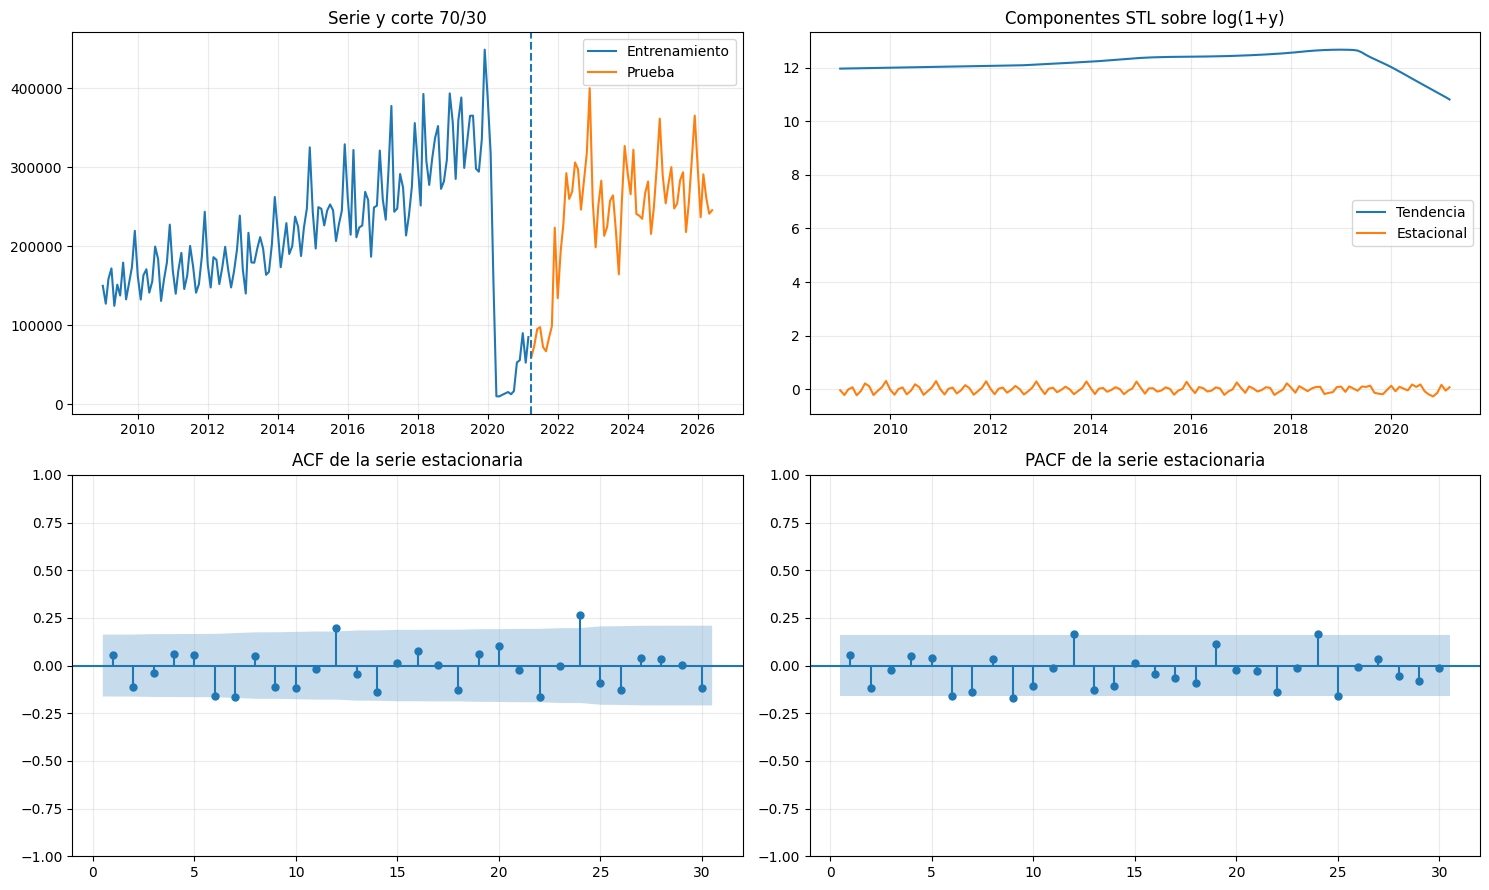

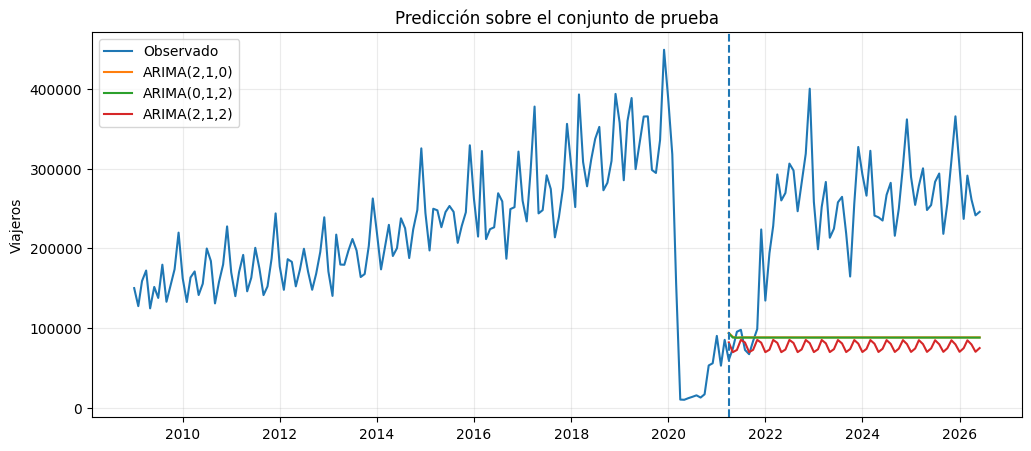

,Serie,Modelo,Orden,Orden estacional,MAE,RMSE,AIC,BIC,Ljung-Box p
0,Total mensual,"ARIMA(2,1,0)","(2, 1, 0)","(0, 0, 0, 12)",156261.294281,170915.018145,90.811536,99.720976,0.999885
1,Total mensual,"ARIMA(0,1,2)","(0, 1, 2)","(0, 0, 0, 12)",156513.337391,171210.540598,91.613484,100.502018,1.000000
2,Total mensual,"ARIMA(2,1,2)","(2, 1, 2)","(0, 0, 0, 12)",165701.092564,180457.503838,77.738460,92.552683,0.032269
3,Total mensual,Suavizamiento exponencial simple,,,165372.541109,180598.233223,NaN,NaN,NaN
4,Total mensual,Holt-Winters aditivo,,,172351.721388,184529.717701,NaN,NaN,NaN
5,Total mensual,Seasonal naive,,,207321.637396,219663.869357,NaN,NaN,NaN
6,Total mensual,"SARIMA(2,1,2)(1,0,1,12)","(2, 1, 2)","(1, 0, 1, 12)",210905.805143,225573.474879,72.859299,92.985681,0.001081
7,Total mensual,Prophet - respaldo aditivo,,,239790.762258,252070.380837,NaN,NaN,NaN


### Región - América Del Centro

Inicio: 2009-01 | Fin: 2026-06 | Frecuencia: Mensual (12 por año)
p=2, d=1, q=2 | Mejor modelo: ARIMA(2,1,0)


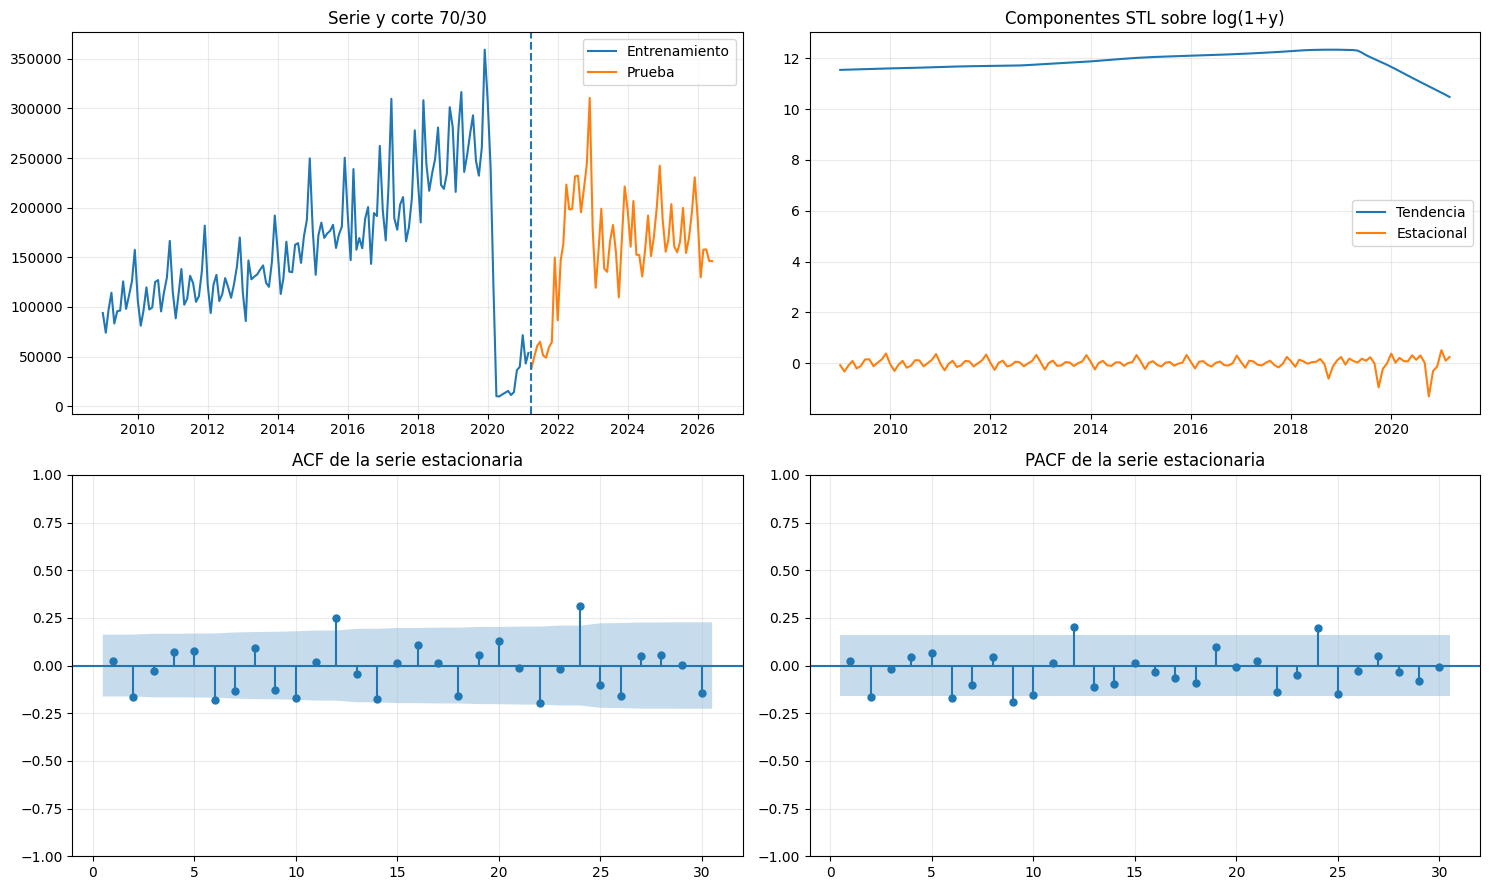

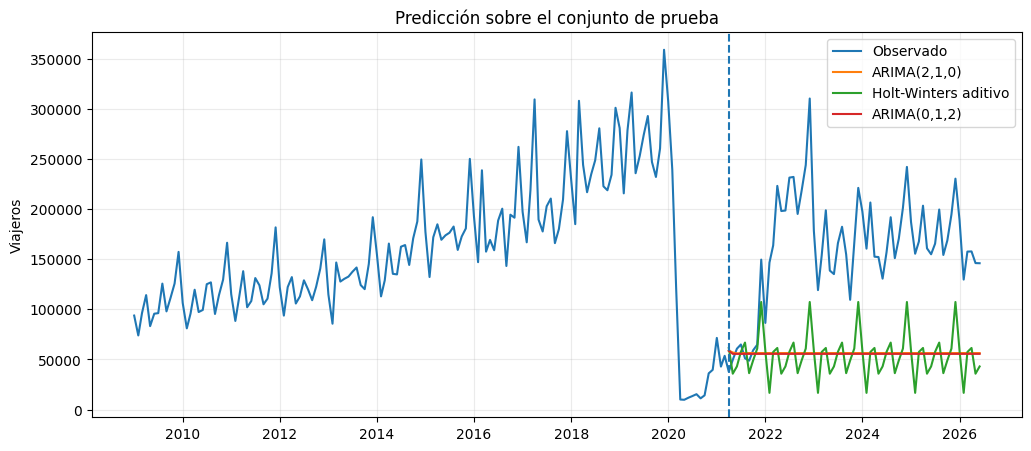

,Serie,Modelo,Orden,Orden estacional,MAE,RMSE,AIC,BIC,Ljung-Box p
8,Región - América Del Centro,"ARIMA(2,1,0)","(2, 1, 0)","(0, 0, 0, 12)",105942.017828,117899.502416,81.444233,90.353673,0.999483
9,Región - América Del Centro,Holt-Winters aditivo,,,108397.642685,117988.204169,NaN,NaN,NaN
10,Región - América Del Centro,"ARIMA(0,1,2)","(0, 1, 2)","(0, 0, 0, 12)",106629.108637,118609.750629,82.316376,91.204910,1.000000
11,Región - América Del Centro,Suavizamiento exponencial simple,,,109866.611643,121961.408693,NaN,NaN,NaN
12,Región - América Del Centro,"ARIMA(2,1,2)","(2, 1, 2)","(0, 0, 0, 12)",116035.605603,128167.190521,69.508933,84.323156,0.042232
13,Región - América Del Centro,Seasonal naive,,,134400.175117,144899.302913,NaN,NaN,NaN
14,Región - América Del Centro,"SARIMA(2,1,2)(1,0,1,12)","(2, 1, 2)","(1, 0, 1, 12)",142455.300204,153418.707947,59.760003,79.886384,0.002146
15,Región - América Del Centro,Prophet - respaldo aditivo,,,159524.402812,169109.411371,NaN,NaN,NaN


### Región - América Del Norte

Inicio: 2009-01 | Fin: 2026-06 | Frecuencia: Mensual (12 por año)
p=2, d=1, q=2 | Mejor modelo: ARIMA(2,1,0)


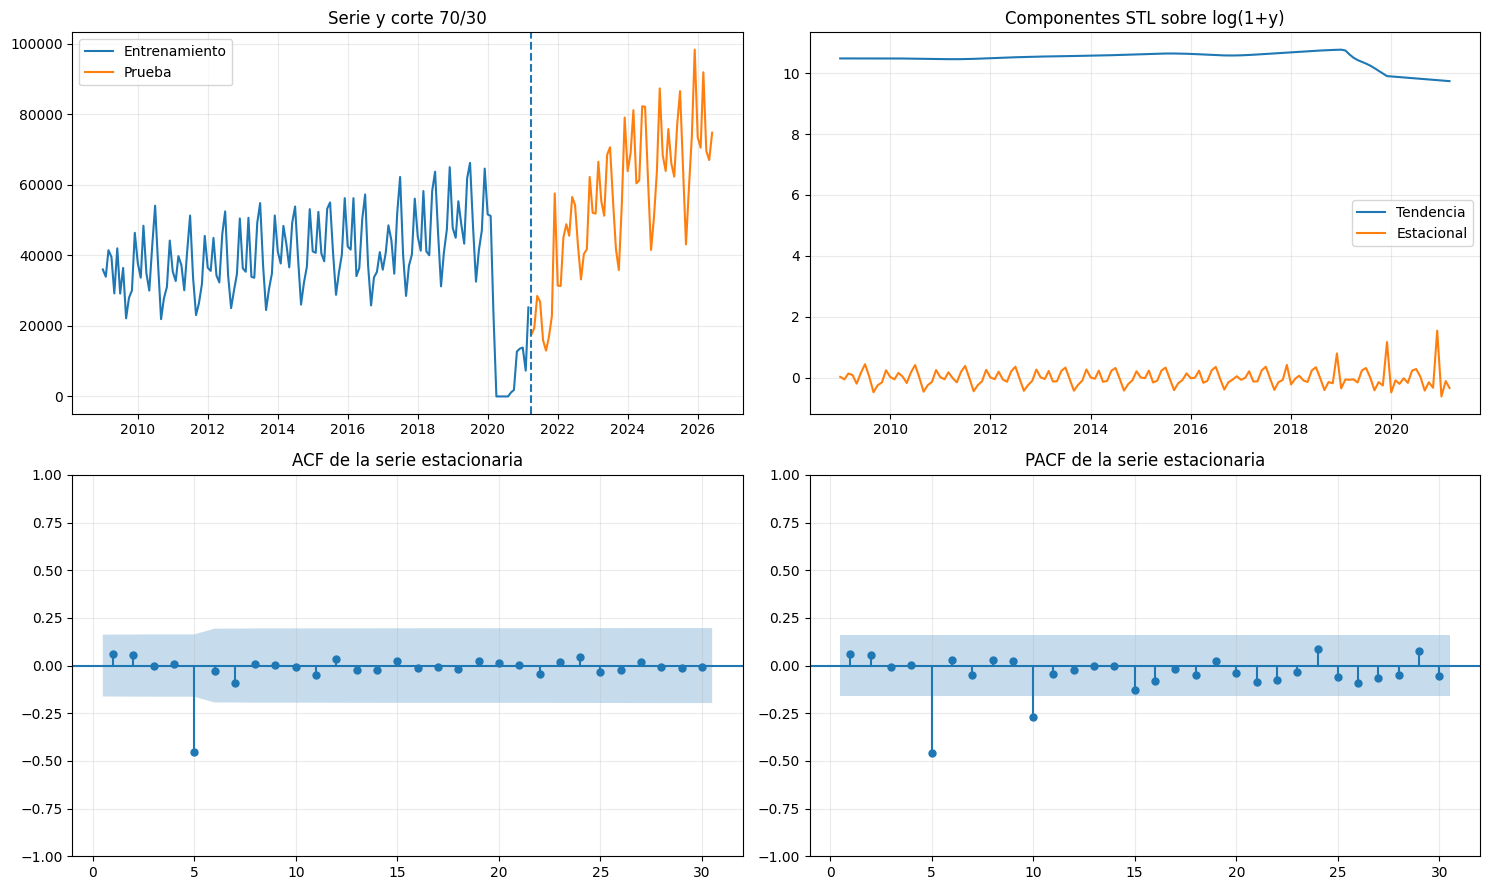

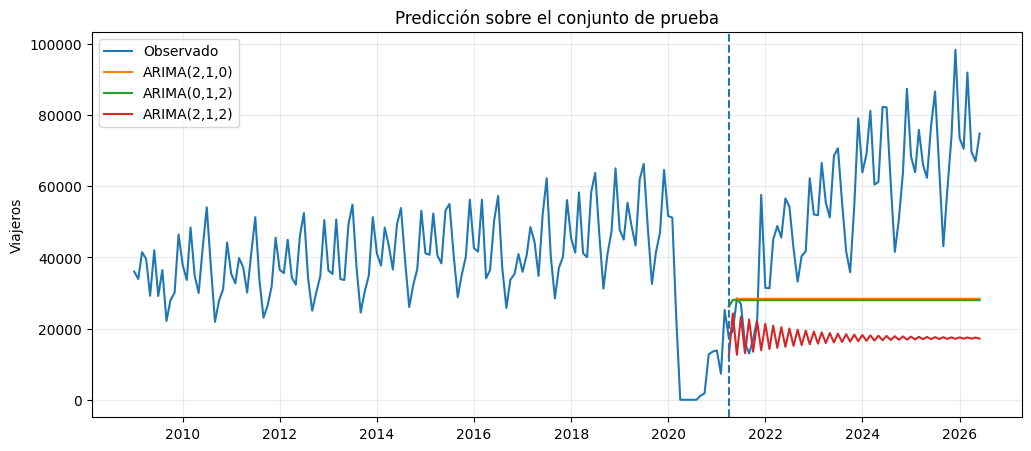

,Serie,Modelo,Orden,Orden estacional,MAE,RMSE,AIC,BIC,Ljung-Box p
16,Región - América Del Norte,"ARIMA(2,1,0)","(2, 1, 0)","(0, 0, 0, 12)",29651.253212,34120.081860,435.150282,444.059722,0.572056
17,Región - América Del Norte,"ARIMA(0,1,2)","(0, 1, 2)","(0, 0, 0, 12)",29977.523382,34452.590075,433.217060,442.105594,0.567938
18,Región - América Del Norte,"ARIMA(2,1,2)","(2, 1, 2)","(0, 0, 0, 12)",39000.120221,43633.400313,429.595162,444.409385,0.257291
19,Región - América Del Norte,Suavizamiento exponencial simple,,,39603.739407,44300.516669,NaN,NaN,NaN
20,Región - América Del Norte,Holt-Winters aditivo,,,40792.037018,44313.058435,NaN,NaN,NaN
21,Región - América Del Norte,Seasonal naive,,,49974.107806,53533.367253,NaN,NaN,NaN
22,Región - América Del Norte,"SARIMA(2,1,2)(1,0,1,12)","(2, 1, 2)","(1, 0, 1, 12)",52869.840177,56832.930896,402.348343,422.474725,0.067127
23,Región - América Del Norte,Prophet - respaldo aditivo,,,55972.690299,59479.369070,NaN,NaN,NaN


### Región - Europa

Inicio: 2009-01 | Fin: 2026-06 | Frecuencia: Mensual (12 por año)
p=2, d=2, q=1 | Mejor modelo: Suavizamiento exponencial simple


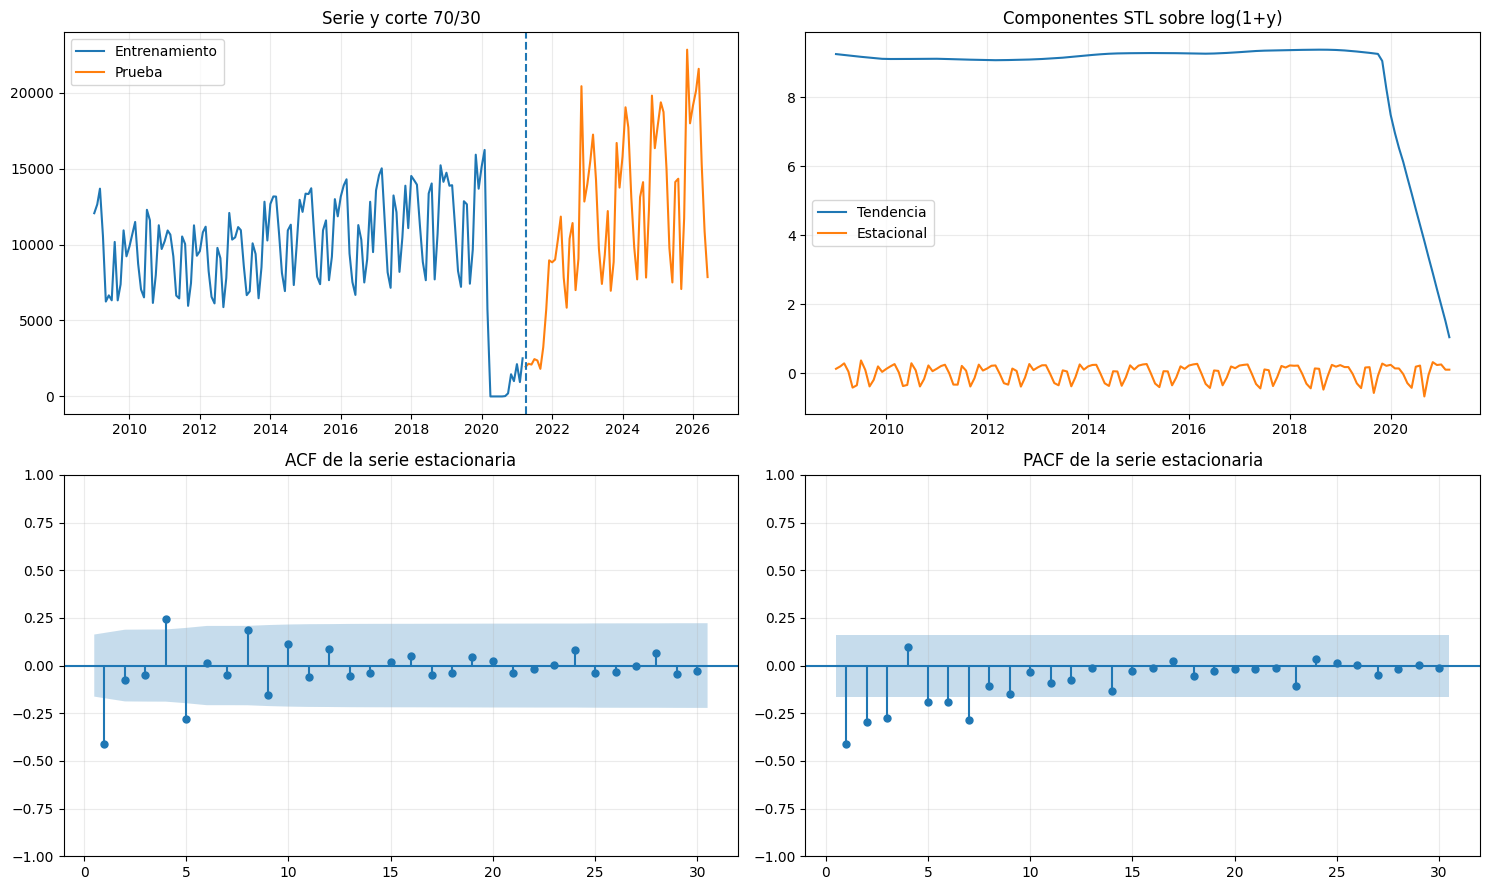

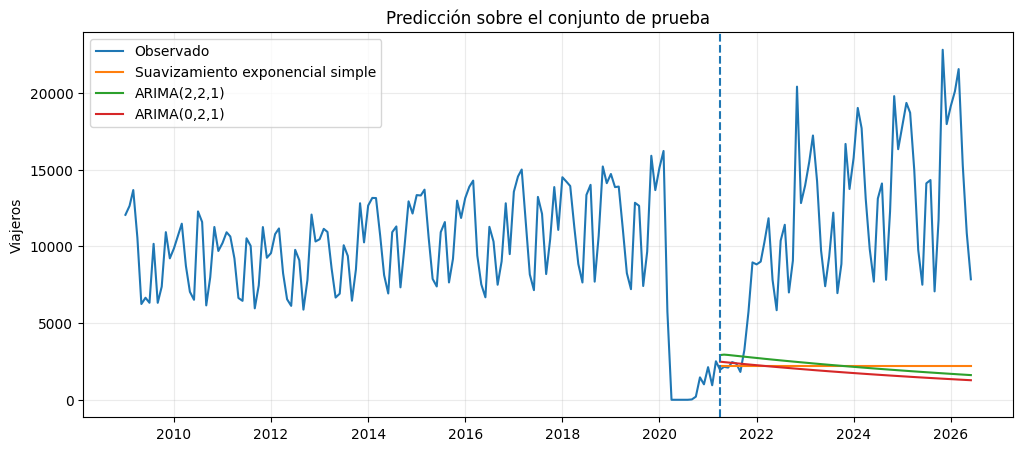

,Serie,Modelo,Orden,Orden estacional,MAE,RMSE,AIC,BIC,Ljung-Box p
24,Región - Europa,Suavizamiento exponencial simple,,,9.571370e+03,1.097813e+04,NaN,NaN,NaN
25,Región - Europa,"ARIMA(2,2,1)","(2, 2, 1)","(0, 0, 0, 12)",9.650618e+03,1.107407e+04,373.046076,384.897454,0.176269
26,Región - Europa,"ARIMA(0,2,1)","(0, 2, 1)","(0, 0, 0, 12)",9.972682e+03,1.141451e+04,372.197469,378.123158,0.565523
27,Región - Europa,Seasonal naive,,,1.107547e+04,1.213451e+04,NaN,NaN,NaN
28,Región - Europa,Holt-Winters aditivo,,,1.115603e+04,1.229354e+04,NaN,NaN,NaN
29,Región - Europa,"SARIMA(2,2,1)(1,0,1,12)","(2, 2, 1)","(1, 0, 1, 12)",1.141438e+04,1.259421e+04,348.062032,365.313216,0.100950
30,Región - Europa,Prophet - respaldo aditivo,,,1.173126e+04,1.292218e+04,NaN,NaN,NaN
31,Región - Europa,"ARIMA(2,2,0)","(2, 2, 0)","(0, 0, 0, 12)",2.780629e+13,1.000167e+14,404.832689,413.721223,0.204196


### Frontera - 01 La Aurora

Inicio: 2009-01 | Fin: 2026-06 | Frecuencia: Mensual (12 por año)
p=2, d=1, q=2 | Mejor modelo: ARIMA(0,1,2)


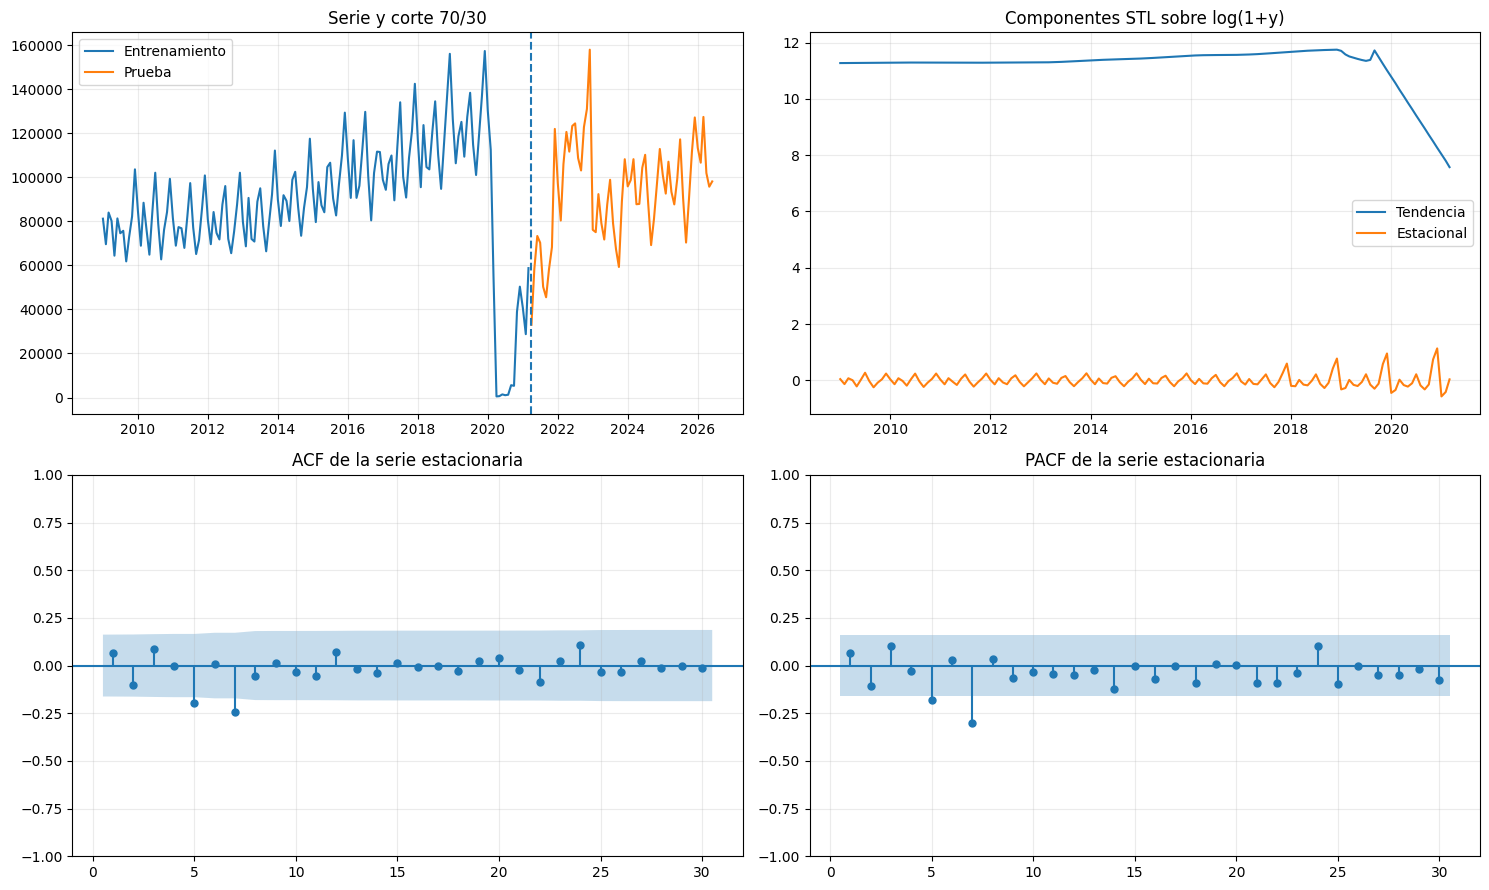

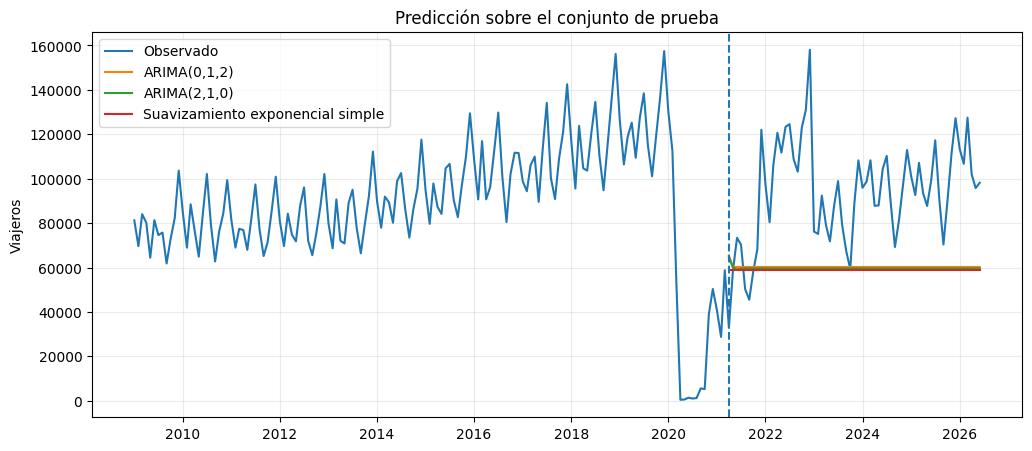

,Serie,Modelo,Orden,Orden estacional,MAE,RMSE,AIC,BIC,Ljung-Box p
32,Frontera - 01 La Aurora,"ARIMA(0,1,2)","(0, 1, 2)","(0, 0, 0, 12)",35683.880322,40874.338715,205.698771,214.587305,0.999998
33,Frontera - 01 La Aurora,"ARIMA(2,1,0)","(2, 1, 0)","(0, 0, 0, 12)",36222.623140,41410.786526,206.414216,215.323656,0.999914
34,Frontera - 01 La Aurora,Suavizamiento exponencial simple,,,36821.786048,42053.317869,NaN,NaN,NaN
35,Frontera - 01 La Aurora,Holt-Winters aditivo,,,38905.203836,42895.071802,NaN,NaN,NaN
36,Frontera - 01 La Aurora,"ARIMA(2,1,2)","(2, 1, 2)","(0, 0, 0, 12)",44097.704818,50183.619485,205.701717,220.515940,0.005382
37,Frontera - 01 La Aurora,Seasonal naive,,,75518.440370,79320.759727,NaN,NaN,NaN
38,Frontera - 01 La Aurora,"SARIMA(2,1,2)(1,0,1,12)","(2, 1, 2)","(1, 0, 1, 12)",76949.734479,80282.735150,185.628281,205.754662,0.000010
39,Frontera - 01 La Aurora,Prophet - respaldo aditivo,,,93550.368330,96413.178304,NaN,NaN,NaN


### Frontera - 07 Valle Nuevo

Inicio: 2009-01 | Fin: 2026-06 | Frecuencia: Mensual (12 por año)
p=2, d=1, q=1 | Mejor modelo: Holt-Winters aditivo


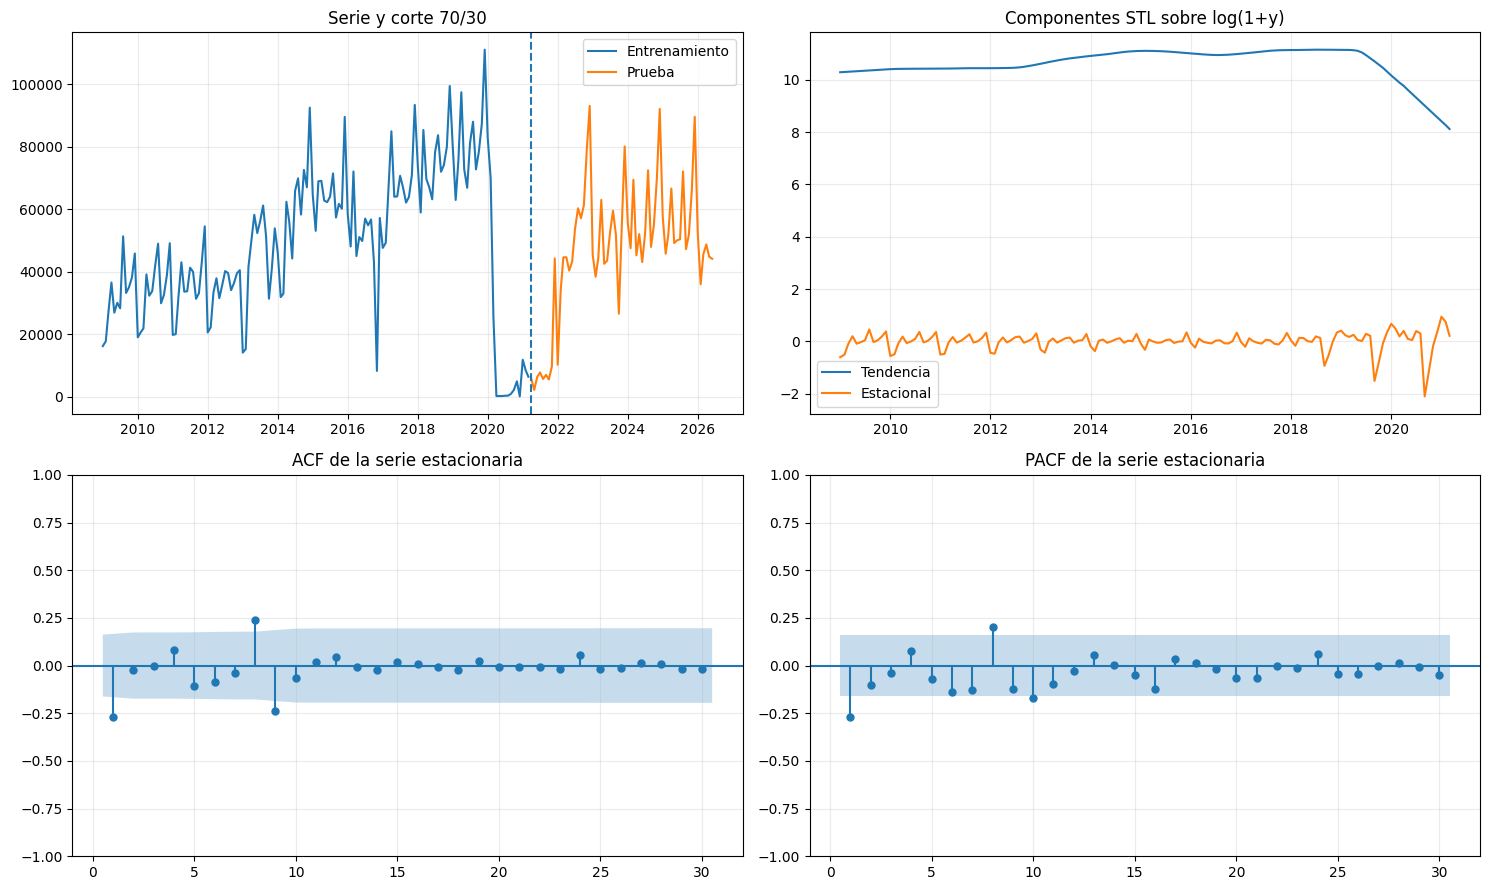

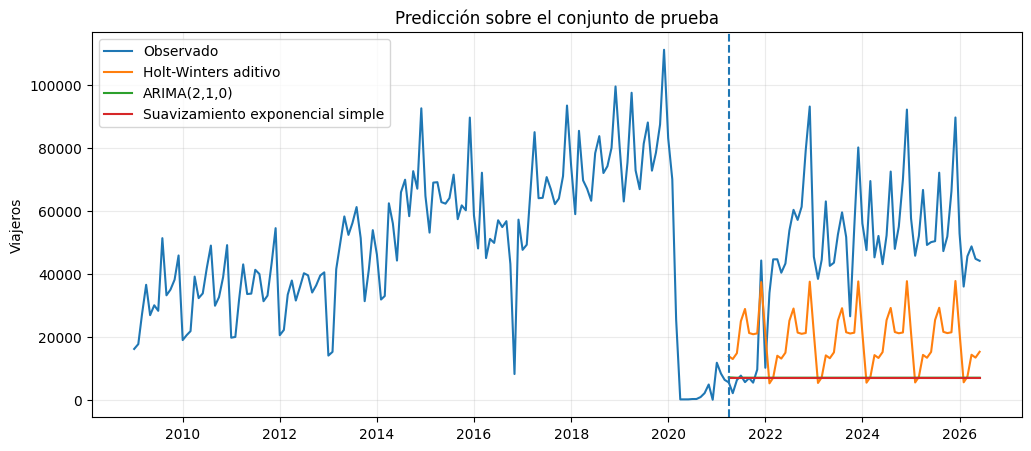

,Serie,Modelo,Orden,Orden estacional,MAE,RMSE,AIC,BIC,Ljung-Box p
40,Frontera - 07 Valle Nuevo,Holt-Winters aditivo,,,32214.480765,34625.480840,NaN,NaN,NaN
41,Frontera - 07 Valle Nuevo,"ARIMA(2,1,0)","(2, 1, 0)","(0, 0, 0, 12)",40764.915280,45655.403417,329.163821,338.073261,0.939853
42,Frontera - 07 Valle Nuevo,Suavizamiento exponencial simple,,,40769.931445,45662.795273,NaN,NaN,NaN
43,Frontera - 07 Valle Nuevo,"ARIMA(2,1,1)","(2, 1, 1)","(0, 0, 0, 12)",41153.432558,46071.528868,331.004503,342.883756,0.976987
44,Frontera - 07 Valle Nuevo,"ARIMA(0,1,1)","(0, 1, 1)","(0, 0, 0, 12)",41310.723524,46236.988549,327.139472,333.079099,0.978590
45,Frontera - 07 Valle Nuevo,"SARIMA(2,1,1)(1,0,1,12)","(2, 1, 1)","(1, 0, 1, 12)",43946.598823,48772.690087,315.599119,332.895930,0.815899
46,Frontera - 07 Valle Nuevo,Seasonal naive,,,44707.230288,49660.588091,NaN,NaN,NaN
47,Frontera - 07 Valle Nuevo,Prophet - respaldo aditivo,,,47493.977637,52030.437239,NaN,NaN,NaN


### Frontera - 09 San Cristóbal

Inicio: 2009-01 | Fin: 2026-06 | Frecuencia: Mensual (12 por año)
p=2, d=2, q=1 | Mejor modelo: Suavizamiento exponencial simple


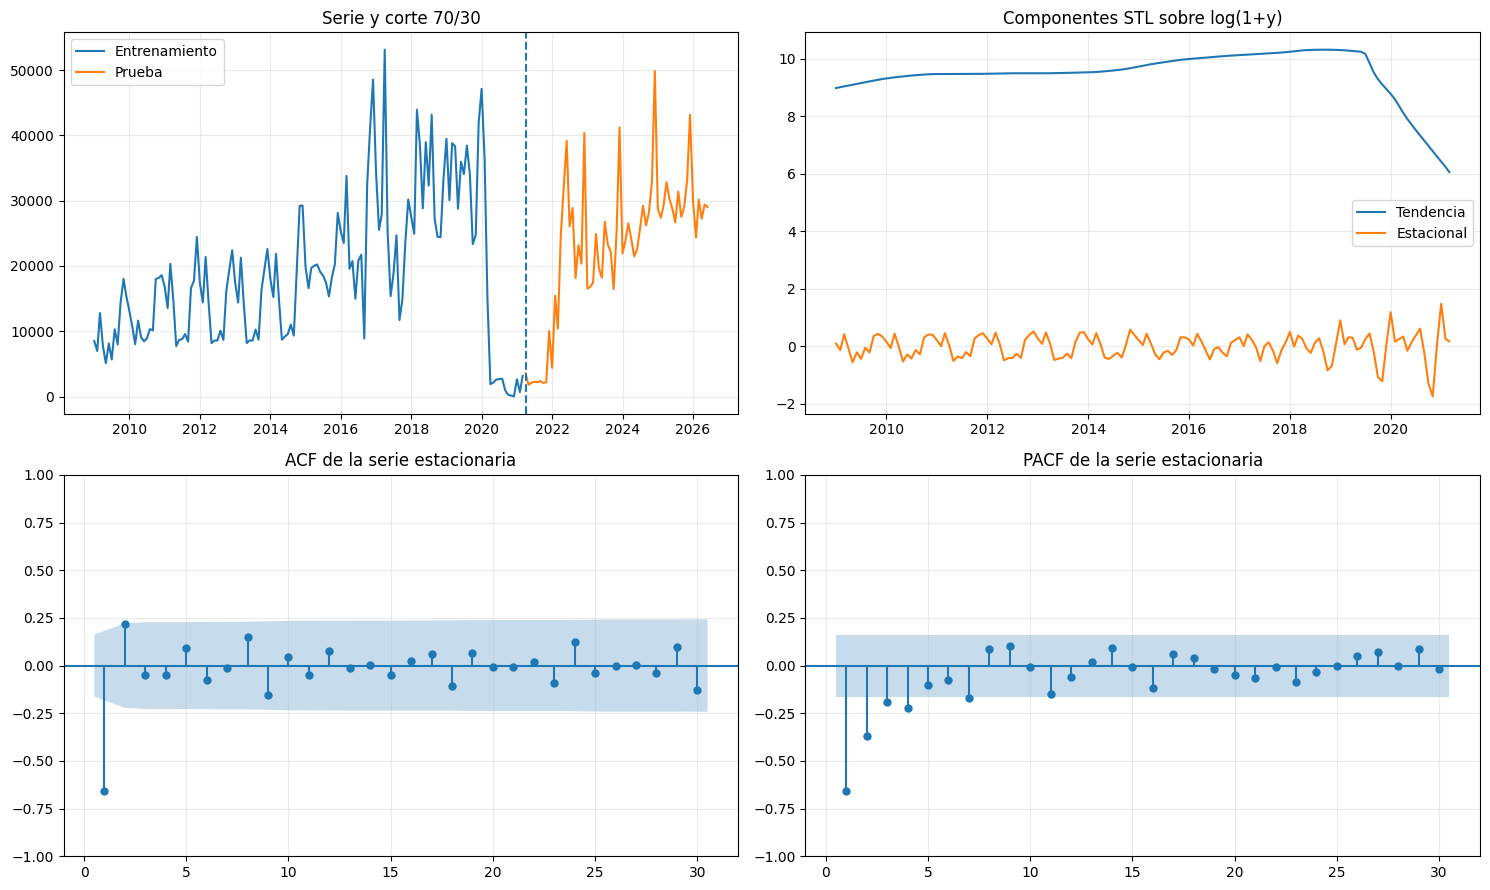

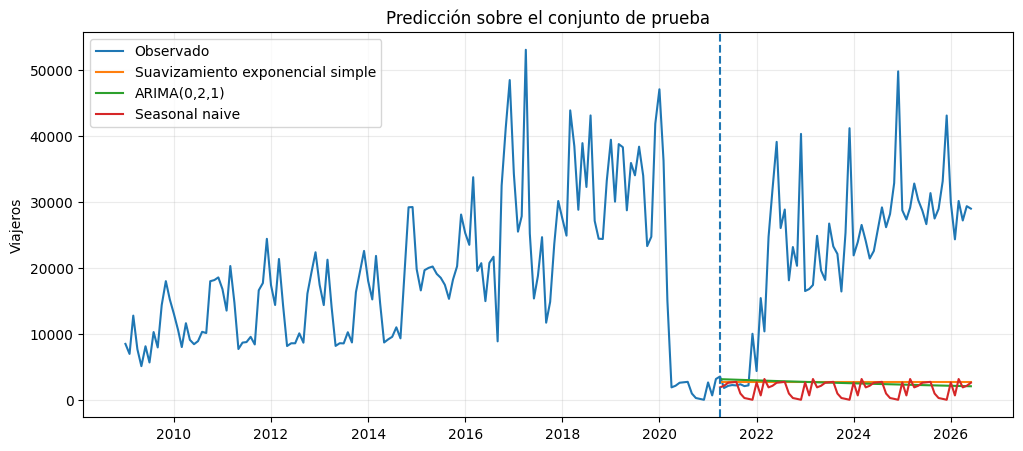

,Serie,Modelo,Orden,Orden estacional,MAE,RMSE,AIC,BIC,Ljung-Box p
48,Frontera - 09 San Cristóbal,Suavizamiento exponencial simple,,,2.048331e+04,2.309175e+04,NaN,NaN,NaN
49,Frontera - 09 San Cristóbal,"ARIMA(0,2,1)","(0, 2, 1)","(0, 0, 0, 12)",2.067378e+04,2.329075e+04,288.554875,294.480564,0.000567
50,Frontera - 09 San Cristóbal,Seasonal naive,,,2.140795e+04,2.405252e+04,NaN,NaN,NaN
51,Frontera - 09 San Cristóbal,Holt-Winters aditivo,,,2.169449e+04,2.406828e+04,NaN,NaN,NaN
52,Frontera - 09 San Cristóbal,"ARIMA(2,2,1)","(2, 2, 1)","(0, 0, 0, 12)",2.139433e+04,2.407597e+04,277.985822,289.837200,0.291552
53,Frontera - 09 San Cristóbal,"SARIMA(2,2,1)(1,0,1,12)","(2, 2, 1)","(1, 0, 1, 12)",2.286604e+04,2.539565e+04,255.843866,273.095049,0.065740
54,Frontera - 09 San Cristóbal,Prophet - respaldo aditivo,,,2.302196e+04,2.547718e+04,NaN,NaN,NaN
55,Frontera - 09 San Cristóbal,"ARIMA(2,2,0)","(2, 2, 0)","(0, 0, 0, 12)",1.080863e+30,5.897049e+30,318.783865,327.672399,0.291496


In [10]:
for name, s in series_df.items():
    obj = analysis_objects[name]
    row = info_df[info_df["Serie"] == name].iloc[0]
    display(Markdown(f"### {name}"))
    print(f"Inicio: {row['Inicio']} | Fin: {row['Fin']} | Frecuencia: {row['Frecuencia']}")
    print(f"p={row['p sugerido']}, d={row['d']}, q={row['q sugerido']} | Mejor modelo: {row['Mejor modelo']}")

    fig, axes = plt.subplots(2, 2, figsize=(15, 9))
    axes[0,0].plot(s.index[:split], s.iloc[:split], label="Entrenamiento")
    axes[0,0].plot(s.index[split:], s.iloc[split:], label="Prueba")
    axes[0,0].axvline(s.index[split], linestyle="--")
    axes[0,0].set_title("Serie y corte 70/30"); axes[0,0].legend()

    axes[0,1].plot(s.index[:split], obj["stl"].trend, label="Tendencia")
    axes[0,1].plot(s.index[:split], obj["stl"].seasonal, label="Estacional")
    axes[0,1].set_title("Componentes STL sobre log(1+y)"); axes[0,1].legend()

    lags = min(30, len(obj["stationary"])//2-1)
    plot_acf(obj["stationary"], lags=lags, zero=False, ax=axes[1,0])
    axes[1,0].set_title("ACF de la serie estacionaria")
    plot_pacf(obj["stationary"], lags=lags, zero=False, ax=axes[1,1], method="ywm")
    axes[1,1].set_title("PACF de la serie estacionaria")
    plt.tight_layout(); plt.show()

    local_metrics = metrics_df[metrics_df["Serie"] == name].sort_values("RMSE")
    top_models = local_metrics.head(3)["Modelo"].tolist()
    plt.figure(figsize=(12,5))
    plt.plot(s.index, s.values, label="Observado")
    for model_name in top_models:
        plt.plot(s.index[split:], obj["predictions"][model_name], label=model_name)
    plt.axvline(s.index[split], linestyle="--")
    plt.title("Predicción sobre el conjunto de prueba")
    plt.ylabel("Viajeros"); plt.legend(); plt.show()
    display(local_metrics)


## 8. Comparación final

Se comparan las categorías por fuerza estacional, crecimiento durante la recuperación, volatilidad y caída durante la pandemia. En cada serie el mejor modelo se determina primero por RMSE y luego por MAE.


In [11]:
comparison = pd.DataFrame({
    "Mayor estacionalidad": [info_df.loc[info_df["Fuerza estacional"].idxmax(), "Serie"]],
    "Mayor crecimiento de recuperación": [info_df.loc[info_df["Crecimiento recuperación"].idxmax(), "Serie"]],
    "Mayor volatilidad": [info_df.loc[info_df["Volatilidad"].idxmax(), "Serie"]],
    "Mayor caída por pandemia": [info_df.loc[info_df["Caída pandemia"].idxmax(), "Serie"]],
})
display(comparison.T.rename(columns={0:"Resultado"}))

display(info_df[["Serie", "Fuerza estacional", "Crecimiento recuperación", "Volatilidad", "Caída pandemia", "Mejor modelo", "RMSE mejor"]]
        .sort_values("RMSE mejor"))


,Resultado
Mayor estacionalidad,Frontera - 09 San Cristóbal
Mayor crecimiento de recuperación,Frontera - 09 San Cristóbal
Mayor volatilidad,Región - América Del Norte
Mayor caída por pandemia,Frontera - 07 Valle Nuevo


,Serie,Fuerza estacional,Crecimiento recuperación,Volatilidad,Caída pandemia,Mejor modelo,RMSE mejor
3,Región - Europa,0.075274,0.008169,0.741292,0.941388,Suavizamiento exponencial simple,10978.125393
6,Frontera - 09 San Cristóbal,0.255294,0.011645,0.580343,0.951139,Suavizamiento exponencial simple,23091.747913
2,Región - América Del Norte,0.000000,0.011457,0.907101,0.874370,"ARIMA(2,1,0)",34120.081860
5,Frontera - 07 Valle Nuevo,0.000000,0.004930,0.691867,0.963079,Holt-Winters aditivo,34625.480840
4,Frontera - 01 La Aurora,0.056836,-0.000124,0.425293,0.842434,"ARIMA(0,1,2)",40874.338715
1,Región - América Del Centro,0.003804,-0.001443,0.300612,0.898435,"ARIMA(2,1,0)",117899.502416
0,Total mensual,0.030092,0.002529,0.300326,0.896958,"ARIMA(2,1,0)",170915.018145


## 9. Conclusiones

1. La pandemia introduce una ruptura estructural que ningún modelo basado únicamente en la historia previa puede anticipar completamente. Por eso el error de prueba debe interpretarse considerando ese evento extraordinario.
2. La transformación `log(1+y)` ayuda a estabilizar la varianza y la mayoría de las series requiere al menos una diferenciación para alcanzar estacionariedad en media.
3. La estacionalidad anual es visible en varias categorías, por lo que Holt-Winters, seasonal naive y SARIMA son referencias especialmente relevantes.
4. No existe un único modelo que domine en todas las series. La selección debe hacerse por serie y apoyarse en RMSE, MAE, AIC/BIC y diagnóstico de residuos.
5. Para INGUAT, los resultados son útiles para planificar recursos por frontera, anticipar meses de mayor demanda y diferenciar la recuperación de los mercados regionales.

El informe en PDF desarrolla estas interpretaciones con mayor detalle y sin incluir código.
